# Emotion Recognition from Dialogue Text

**Project #5 - Emotion Recognition from Text.** Predict the emotion a speaker expresses in each turn of a conversation.

| | |
|---|---|
| **Task** | 7-way single-label classification of a dialogue turn: *neutral, joy, surprise, anger, sadness, disgust, fear* |
| **Data** | MELD (Poria et al., 2019): 13,708 utterances from 1,433 dialogues of the TV series *Friends* |
| **Models** | Majority-class and TF-IDF + Logistic Regression baselines; RoBERTa-base fine-tuned with and without dialogue context |
| **Metrics** | Accuracy, precision, recall, F1 (weighted = standard on MELD, and macro = all emotions equal) |

### 1. Problem understanding

**Who needs this?** Chatbots and virtual assistants that should respond empathetically ("I'm sorry to hear that" vs "Congrats!"), customer-support tools that flag angry customers for escalation, and social-media / mental-health analytics that track emotional tone.

**What makes it hard?**
1. **Conversational text is short and ambiguous.** Half of MELD's utterances have 6 words or fewer. *"Come on!"* can be joyful or angry; the **previous turns** tell which. So the model should read the dialogue context, but only *past* turns (a live chatbot never sees the future).
2. **Heavy class imbalance.** 47% of utterances are neutral; fear and disgust are under 3% each. A model that always says "neutral" already gets ~48% accuracy, so accuracy alone is misleading and we report **macro-F1** as well.
3. **Missing modalities.** MELD annotators watched the video; tone of voice and facial expressions are not in the text, which caps what a text model can reach (published text-only systems score about 0.60-0.67 weighted-F1).

**Constraints:** trained and evaluated on a 4-core CPU without a GPU, so the model must fine-tune in under an hour; inference must be fast enough for an interactive demo (well under a second per message).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.emotion.config import LABELS, RESULTS_DIR, FIGURES_DIR, DEFAULT_TRANSFORMER_DIR, SEED
from src.emotion.data import load_all, add_context, clean_text, model_input
from src.emotion.evaluate import compute_metrics, report, plot_confusion
from src.emotion import baseline as bl

np.random.seed(SEED); torch.manual_seed(SEED)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("torch", torch.__version__, "| project root:", ROOT)

torch 2.15.0+cu132 | project root: /home/user/NLP-Project


## 2. Dataset

**Why MELD?** The assignment asks for emotions *from dialogues*. MELD is the standard benchmark for emotion recognition in conversation: real multi-party dialogues, a label for every turn, and an official train/dev/test split (so results are comparable with published work). Its seven classes are Ekman's six basic emotions plus neutral, which matches the task description (joy, sadness, anger, ...). The CSVs (1.5 MB) are included in `data/raw/`.

In [2]:
splits = load_all()
train, dev, test = splits["train"], splits["dev"], splits["test"]
for name, df in splits.items():
    print(f"{name:5s}: {len(df):5d} utterances, {df.dialogue_id.nunique():4d} dialogues")
train.head(8)

train:  9989 utterances, 1038 dialogues
dev  :  1109 utterances,  114 dialogues
test :  2610 utterances,  280 dialogues


,dialogue_id,utterance_id,speaker,text,emotion,label
0,0,0,Chandler,also I was the point person on my company's transition from the KL-5 to GR-6 system.,neutral,0
1,0,1,The Interviewer,You must've had your hands full.,neutral,0
2,0,2,Chandler,That I did. That I did.,neutral,0
3,0,3,The Interviewer,So let's talk a little bit about your duties.,neutral,0
4,0,4,Chandler,My duties? All right.,surprise,2
5,0,5,The Interviewer,"Now you'll be heading a whole division, so you'll have a lot of duties.",neutral,0
6,0,6,Chandler,I see.,neutral,0
7,0,7,The Interviewer,But there'll be perhaps 30 people under you so you can dump a certain amount on them.,neutral,0


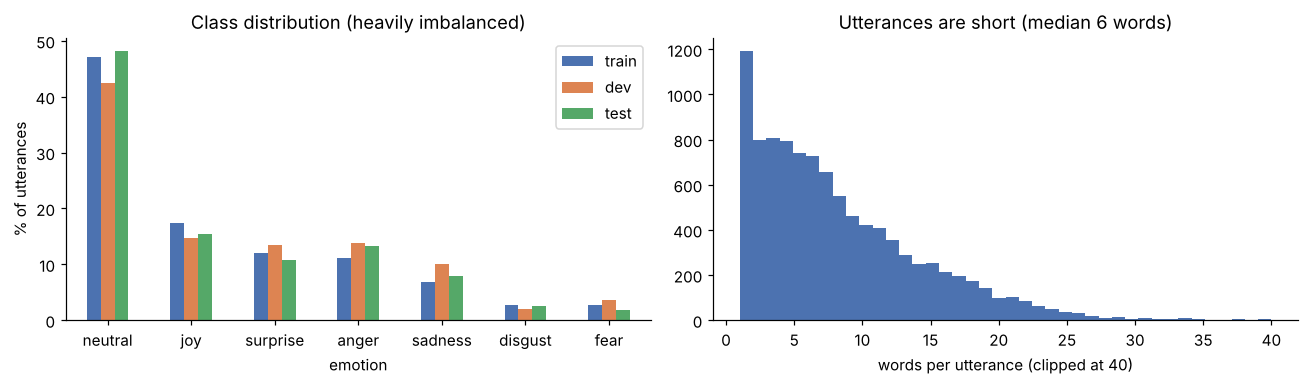

          train   dev  test
emotion                    
neutral    47.2  42.4  48.1
joy        17.4  14.7  15.4
surprise   12.1  13.5  10.8
anger      11.1  13.8  13.2
sadness     6.8  10.0   8.0
disgust     2.7   2.0   2.6
fear        2.7   3.6   1.9


In [3]:
dist = pd.DataFrame({s: df.emotion.value_counts(normalize=True) for s, df in splits.items()}).loc[LABELS]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
(dist * 100).plot.bar(ax=axes[0], rot=0, color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set_ylabel("% of utterances"); axes[0].set_title("Class distribution (heavily imbalanced)")
lens = train.text.str.split().str.len()
axes[1].hist(lens.clip(upper=40), bins=40, color="#4c72b0")
axes[1].set_xlabel("words per utterance (clipped at 40)"); axes[1].set_title(f"Utterances are short (median {lens.median():.0f} words)")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "data_overview.png", dpi=150); plt.show()
print((dist * 100).round(1).to_string())

**Observations.** Neutral dominates (47%), and fear and disgust are rare (about 270 training examples each). The label distribution is similar across splits, so the test set is representative. Utterances are very short (median 6 words), which motivates using dialogue context.

## 3. Preprocessing pipeline

Implemented in `src/emotion/data.py`:
1. **Unicode / punctuation normalisation:** curly quotes, dashes and ellipses become ASCII, and whitespace is collapsed. Case, punctuation and repeated letters are **kept on purpose**: "WHAT?!" and "what." express different emotions.
2. **No stop-word removal, stemming or lower-casing for the transformer.** RoBERTa's byte-level BPE tokenizer handles any string, and function words ("not", "so", "never") matter for emotion.
3. **Dialogue context.** For every utterance we take the *previous two turns* of the same dialogue (past only). Speaker names are dropped so the model cannot learn character-specific shortcuts that would not transfer to real users.
4. **Model input** = `<s> target utterance </s></s> context </s>`. The target comes first so it is never truncated; overly long contexts are trimmed from the oldest side (max 128 tokens).

In [4]:
print(repr("I’m so… tired — honestly"), "->", repr(clean_text("I’m so… tired — honestly")))
ctx_test = add_context(test, n_turns=2)
example = ctx_test[ctx_test.dialogue_id == ctx_test.dialogue_id.iloc[40]].head(5)
example[["speaker", "text", "context", "emotion"]]

'I’m so… tired — honestly' -> "I'm so... tired - honestly"


,speaker,text,context,emotion
38,Chandler,You're coming on to the entire room! I'm Chandler.,,anger
39,Chandler,Hi.,You're coming on to the entire room! I'm Chandler.,neutral
40,Marjorie,Hi.,You're coming on to the entire room! I'm Chandler. | Hi.,neutral
41,Chandler,You mind if I,Hi. | Hi.,neutral
42,Marjorie,"No, please.",Hi. | You mind if I,neutral


In [5]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(DEFAULT_TRANSFORMER_DIR)
a, b = model_input("What?", "I'm getting married. | To Emily. Next week.")
ids = tok(a, b)["input_ids"]
print(len(ids), "tokens:", tok.convert_ids_to_tokens(ids))

18 tokens: ['<s>', 'What', '?', '</s>', '</s>', 'I', "'m", 'Ġgetting', 'Ġmarried', '.', 'Ġ|', 'ĠTo', 'ĠEmily', '.', 'ĠNext', 'Ġweek', '.', '</s>']


## 4. Baselines

* **Majority class:** always predicts "neutral". This is the floor any useful model must beat.
* **TF-IDF + Logistic Regression** (`src/emotion/baseline.py`): word 1-2-grams (emotional words and phrases such as "oh my god") plus character 2-5-grams (punctuation and spelling such as "!!", "?!", "sooo"), with `class_weight="balanced"` for the imbalance. The regularisation strength `C` is tuned on the **dev** set. This strong, interpretable classical model trains in about a minute.

In [6]:
from sklearn.dummy import DummyClassifier
majority = DummyClassifier(strategy="most_frequent").fit(train.text, train.label)
m_major = compute_metrics(test.label, majority.predict(test.text))
print(f"Majority: accuracy {m_major['accuracy']:.3f}, weighted-F1 {m_major['weighted_f1']:.3f}, macro-F1 {m_major['macro_f1']:.3f}")

tfidf, best_C = bl.tune_and_train(train, dev)
pred_tfidf = tfidf.predict(test.text)
m_tfidf = compute_metrics(test.label, pred_tfidf)
print(report(test.label, pred_tfidf))

Majority: accuracy 0.481, weighted-F1 0.313, macro-F1 0.093


  C=0.1   dev macro-F1=0.3551


  C=0.3   dev macro-F1=0.3724


  C=1.0   dev macro-F1=0.3840


  C=3.0   dev macro-F1=0.3792


  C=10.0  dev macro-F1=0.3625
  -> best C=1.0
              precision    recall  f1-score   support

     neutral      0.743     0.617     0.674      1256
         joy      0.496     0.510     0.503       402
    surprise      0.467     0.587     0.521       281
       anger      0.390     0.400     0.395       345
     sadness      0.268     0.337     0.299       208
     disgust      0.183     0.221     0.200        68
        fear      0.077     0.160     0.104        50

    accuracy                          0.527      2610
   macro avg      0.375     0.404     0.385      2610
weighted avg      0.563     0.527     0.541      2610



In [7]:
pd.DataFrame(bl.top_features(tfidf, k=7)).T.rename(columns=lambda i: f"#{i+1}")

,#1,#2,#3,#4,#5,#6,#7
neutral,hey,know,sure,hi,why not,for,ok
joy,love,great,thank,ho,amazing,good,hey
surprise,wow,my god,oh my,whoa,god,oh,really
anger,that it,fine,mad,you win,stop,go,enough
sadness,sorry,hard,old,died,oh come,yeah but,have been
disgust,ugh,ew,am not,bug,pig,disgusting,use
fear,uh,what what,no don,pick up,joey please,scared,does it


The baseline learns sensible cues (*love, great, amazing* → joy; *wow, oh my god, whoa* → surprise; *ugh, ew, disgusting* → disgust; *sorry, died* → sadness). But it cannot handle negation ("not happy"), word order or context, and it struggles with fear and disgust.

## 5. Fine-tuned transformer: RoBERTa-base + dialogue context

**Why RoBERTa?** It is a 125M-parameter transformer pre-trained on 160 GB of English text, including web and conversational-style data, and it is a standard strong encoder for emotion classification. Pre-training already encodes negation, intensity and idioms. Fine-tuning adds a small classification head on the `<s>` token and updates all weights.

**Training setup** (`src/emotion/train_transformer.py`):
* AdamW, learning rate 2e-5, linear warm-up (6%) and decay, batch 16, 4 epochs, weight decay 0.01, gradient clipping 1.0.
* Cross-entropy with **softened class weights** w ∝ 1/√frequency. Full inverse weights over-predict the rare classes; no weights ignores them.
* **Model selection on dev:** the epoch with the best dev weighted-F1 is kept. The test set is used once.
* CPU-friendly: dynamic padding, length-bucketed batches, bfloat16 autocast (Intel AMX), fused AdamW. One run takes about 40 minutes on 4 CPU cores.
* Base weights: `roberta-base` (MIT licence). The development machine could not reach the Hugging Face Hub, so the encoder was taken from spaCy's `en_core_web_trf` package (which bundles RoBERTa-base) and converted with `scripts/convert_spacy_roberta.py`. `scripts/verify_conversion.py` checks that every layer matches the reference implementation to within 2e-5.

Training is done by the script (`python -m src.emotion.train_transformer --base-model roberta-base`). Here we **load the fine-tuned model** shipped in `models/roberta-meld-context/` and evaluate it. Set `TRAIN_TRANSFORMER = True` to retrain from scratch (about 40 minutes with AMX, longer on other CPUs).

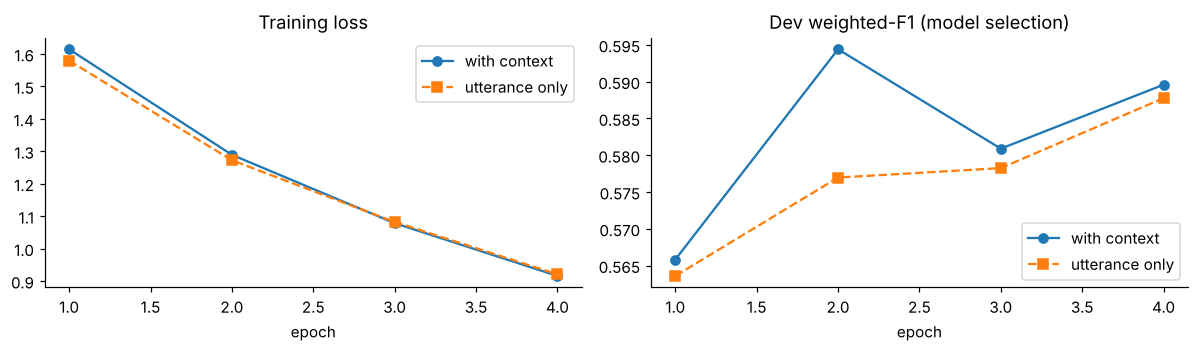

,epoch,train_loss,dev_accuracy,dev_weighted_f1,dev_macro_f1,minutes
0,1,1.6142,0.5816,0.5658,0.3934,8.9971
1,2,1.2889,0.6050,0.5944,0.4426,17.2787
2,3,1.0781,0.5969,0.5809,0.4459,25.1028
3,4,0.9157,0.5906,0.5896,0.4549,33.2558


In [8]:
TRAIN_TRANSFORMER = False
if TRAIN_TRANSFORMER:
    import subprocess
    subprocess.run([sys.executable, "-m", "src.emotion.train_transformer", "--base-model", "roberta-base",
                    "--context-turns", "2"], cwd=ROOT, check=True)
    subprocess.run([sys.executable, "scripts/export_model.py", "runs/roberta_context",
                    str(DEFAULT_TRANSFORMER_DIR)], cwd=ROOT, check=True)

hist = pd.DataFrame(json.loads((RESULTS_DIR / "roberta_context_metrics.json").read_text())["history"])
hist_u = pd.DataFrame(json.loads((RESULTS_DIR / "roberta_utterance_metrics.json").read_text())["history"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(hist.epoch, hist.train_loss, "o-", label="with context"); axes[0].plot(hist_u.epoch, hist_u.train_loss, "s--", label="utterance only")
axes[0].set_title("Training loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(hist.epoch, hist.dev_weighted_f1, "o-", label="with context"); axes[1].plot(hist_u.epoch, hist_u.dev_weighted_f1, "s--", label="utterance only")
axes[1].set_title("Dev weighted-F1 (model selection)"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIGURES_DIR / "training_curves.png", dpi=150); plt.show()
hist.round(4)

In [9]:
import time
from src.emotion.predict import EmotionClassifier
clf = EmotionClassifier()  # models/roberta-meld-context (float32 inference)
contexts = [c.split(" | ") if c else None for c in ctx_test.context]
t0 = time.time()
probs_ctx = clf.predict_proba(list(ctx_test.text), contexts)
print(f"Predicted {len(ctx_test)} test utterances in {time.time() - t0:.0f}s on CPU")
pred_ctx = probs_ctx.argmax(1)
m_ctx = compute_metrics(ctx_test.label, pred_ctx)
print(report(ctx_test.label, pred_ctx))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Predicted 2610 test utterances in 143s on CPU
              precision    recall  f1-score   support

     neutral      0.783     0.788     0.785      1256
         joy      0.634     0.565     0.597       402
    surprise      0.495     0.690     0.577       281
       anger      0.488     0.475     0.482       345
     sadness      0.436     0.341     0.383       208
     disgust      0.225     0.235     0.230        68
        fear      0.080     0.040     0.053        50

    accuracy                          0.638      2610
   macro avg      0.449     0.448     0.444      2610
weighted avg      0.634     0.638     0.633      2610



## 6. Evaluation and comparison

All numbers are on the **held-out test set** (2,610 utterances, never used for training or model selection).
* **Accuracy** is the share of turns labelled correctly.
* **Precision / recall / F1** are computed per class and then averaged. The *weighted* average (by class size) is the standard MELD metric. The *macro* average treats every emotion equally, so it exposes performance on rare classes.

The utterance-only RoBERTa is an **ablation**: the same model and training, but with no context. Its test predictions come from its training run (`results/roberta_utterance_test_probs.npy`).

In [10]:
probs_utt = np.load(RESULTS_DIR / "roberta_utterance_test_probs.npy")
m_utt = compute_metrics(test.label, probs_utt.argmax(1))
models = {"Majority (always neutral)": m_major, "TF-IDF + LogReg": m_tfidf,
          "RoBERTa (utterance only)": m_utt, "RoBERTa + context (final)": m_ctx}
cols = ["accuracy", "weighted_precision", "weighted_recall", "weighted_f1", "macro_precision", "macro_recall", "macro_f1"]
summary = pd.DataFrame({k: {c: v[c] for c in cols} for k, v in models.items()}).T
summary.round(3)

,accuracy,weighted_precision,weighted_recall,weighted_f1,macro_precision,macro_recall,macro_f1
Majority (always neutral),0.481,0.232,0.481,0.313,0.069,0.143,0.093
TF-IDF + LogReg,0.527,0.563,0.527,0.541,0.375,0.404,0.385
RoBERTa (utterance only),0.618,0.628,0.618,0.620,0.449,0.468,0.452
RoBERTa + context (final),0.638,0.634,0.638,0.633,0.449,0.448,0.444


In [11]:
# Robustness: the RoBERTa runs were repeated with 3 random seeds (42, 13, 7).
rows = []
for variant in ["utterance", "context"]:
    for seed_suffix in ["", "_seed13", "_seed7"]:
        p = RESULTS_DIR / f"roberta_{variant}{seed_suffix}_metrics.json"
        if p.exists():
            m = json.loads(p.read_text())
            rows.append({"model": f"RoBERTa ({variant})", "seed": m["args"]["seed"], "accuracy": m["accuracy"],
                         "weighted_f1": m["weighted_f1"], "macro_f1": m["macro_f1"]})
seeds = pd.DataFrame(rows)
if len(seeds):
    agg = seeds.groupby("model")[["accuracy", "weighted_f1", "macro_f1"]].agg(["mean", "std", "count"])
    display(agg.round(3))

accuracy           weighted_f1           macro_f1      \
                        mean std count        mean std count     mean std   
model                                                                       
RoBERTa (context)      0.638 NaN     1       0.633 NaN     1    0.444 NaN   
RoBERTa (utterance)    0.618 NaN     1       0.620 NaN     1    0.452 NaN   

                           
                    count  
model                      
RoBERTa (context)       1  
RoBERTa (utterance)     1

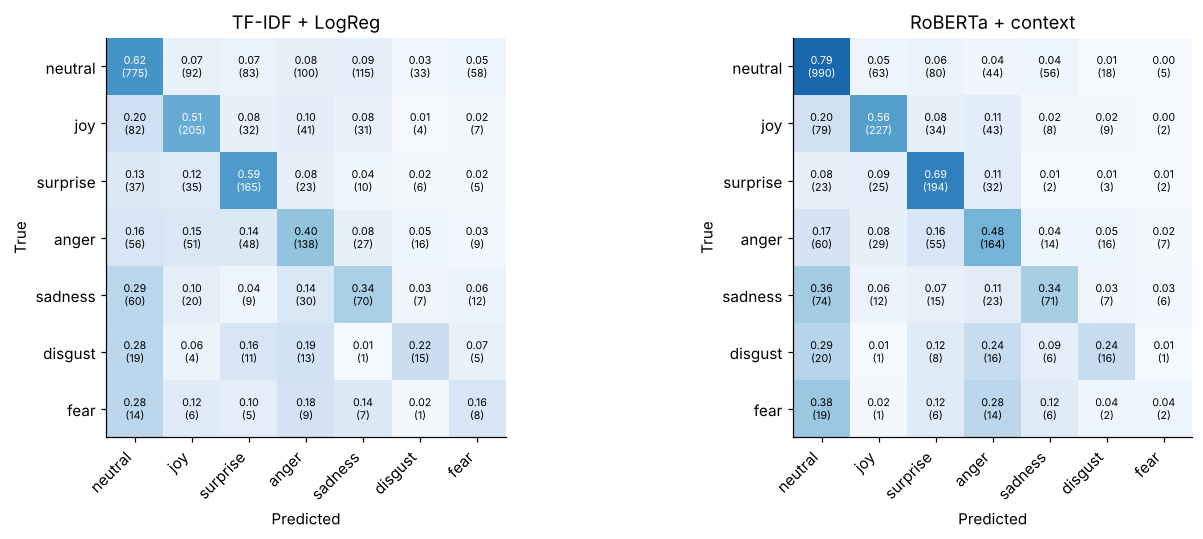

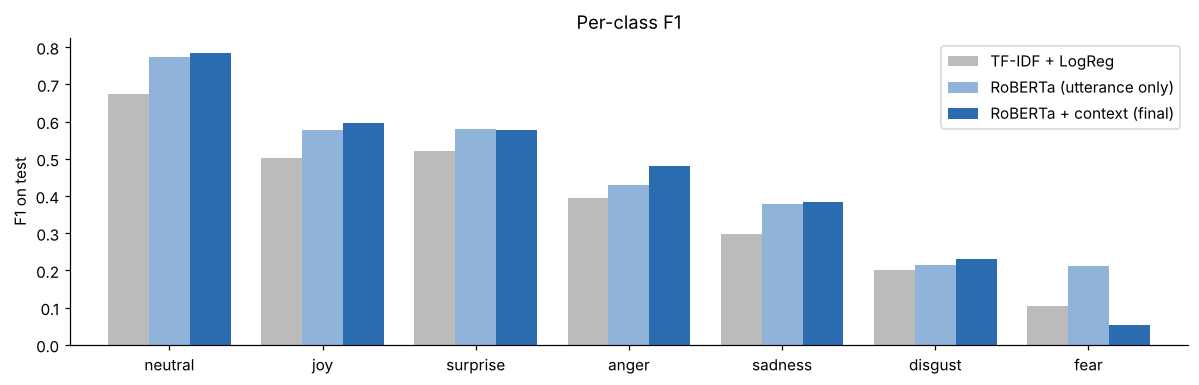

,TF-IDF + LogReg,RoBERTa (utterance only),RoBERTa + context (final)
neutral,0.674,0.773,0.785
joy,0.503,0.577,0.597
surprise,0.521,0.581,0.577
anger,0.395,0.430,0.482
sadness,0.299,0.380,0.383
disgust,0.200,0.214,0.230
fear,0.104,0.212,0.053


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion(test.label, pred_tfidf, "TF-IDF + LogReg", ax=axes[0])
plot_confusion(ctx_test.label, pred_ctx, "RoBERTa + context", ax=axes[1])
plt.tight_layout(); plt.savefig(FIGURES_DIR / "confusion_comparison.png", dpi=150); plt.show()

per_class = pd.DataFrame({k: {l: v["per_class"][l]["f1"] for l in LABELS} for k, v in models.items() if "Majority" not in k})
ax = per_class.plot.bar(figsize=(11, 3.6), rot=0, width=0.8, color=["#bbbbbb", "#8fb3d9", "#2b6cb0"])
ax.set_ylabel("F1 on test"); ax.set_title("Per-class F1"); ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "per_class_f1.png", dpi=150); plt.show()
per_class.round(3)

**Reading the confusion matrices.** Rows are the true emotion and columns the prediction (row-normalised). For five of the six emotions the most frequent error is **predicting neutral**: weakly expressed emotions look neutral in text. Surprise is the exception and is mostly confused with anger. Fear and disgust are the hardest classes, with the fewest examples (50 and 68 in test). RoBERTa beats the baseline on six of the seven classes. **Fear is the exception:** the context model almost never predicts fear (recall 0.04, mostly read as neutral or anger), while the utterance-only model does better there. With only 50 test examples, fear scores are very unstable (see the seed table above).

## 7. Does dialogue context help?

The two RoBERTa models are identical except for the two previous turns given as input. Below are test utterances where the context model is right and the utterance-only model is wrong (and the reverse, for balance).

In [13]:
cmp = ctx_test[["text", "context", "emotion"]].copy()
cmp["utterance_only"] = [LABELS[i] for i in probs_utt.argmax(1)]
cmp["with_context"] = [LABELS[i] for i in pred_ctx]
fixed = cmp[(cmp.with_context == cmp.emotion) & (cmp.utterance_only != cmp.emotion)]
broken = cmp[(cmp.with_context != cmp.emotion) & (cmp.utterance_only == cmp.emotion)]
print(f"Context fixes {len(fixed)} errors and introduces {len(broken)} new ones (net {len(fixed) - len(broken):+d}).")
n_words = cmp.text.str.split().str.len()
analysis = {"fixed": len(fixed), "broken": len(broken)}
print("Accuracy by length of the target utterance:")
for key, name, mask in [("short", "<= 3 words", n_words <= 3), ("medium", "4-8 words", (n_words > 3) & (n_words <= 8)),
                        ("long", "> 8 words", n_words > 8)]:
    acc_u = (cmp.utterance_only[mask] == cmp.emotion[mask]).mean(); acc_c = (cmp.with_context[mask] == cmp.emotion[mask]).mean()
    analysis.update({f"{key}_n": int(mask.sum()), f"{key}_utt": float(acc_u), f"{key}_ctx": float(acc_c)})
    print(f"  {name:10s} n={mask.sum():4d}  utterance-only {acc_u:.3f} -> with context {acc_c:.3f}  ({(acc_c - acc_u) * 100:+.1f} points)")
(RESULTS_DIR / "context_analysis.json").write_text(json.dumps(analysis, indent=2))
fixed[n_words[fixed.index] <= 4].head(10)

Context fixes 189 errors and introduces 139 new ones (net +50).
Accuracy by length of the target utterance:
  <= 3 words n= 715  utterance-only 0.708 -> with context 0.716  (+0.8 points)
  4-8 words  n= 859  utterance-only 0.651 -> with context 0.658  (+0.7 points)
  > 8 words  n=1036  utterance-only 0.530 -> with context 0.567  (+3.7 points)


,text,context,emotion,utterance_only,with_context
42,"No, please.",Hi. | You mind if I,neutral,disgust,neutral
62,Bumpy?,"Well, that makes me feel so good. | It was just so awkward and bumpy.",surprise,neutral,surprise
98,Okay-okay!,"I mean, enough of the silliness! | Well, why don't you tell her to stop being silly!",anger,joy,anger
154,What a wank!,"Don't look honey. Change the channel! Change the channel! | Wait! Wait! I wanna see this. After I divorce him, half ...",anger,joy,anger
156,I know!,"What a wank! | Oh, I cannot believe he's using our divorce to sell mattresses.",anger,surprise,anger
209,Chandler that's crazy!,"Why, exactly? | Because of the weekend, we had a fight.",surprise,disgust,surprise
240,You like it right?,"Oh I see, so this suit is making a point. | Now that you're on you're own, you're free to look as stupid as you like.",neutral,joy,neutral
366,"Who, Josh?","Oh yeah, that was great. Thanks to you, the hottest cocktail waitress there is quitting to teach the third grade! | ...",surprise,neutral,surprise
418,"""Can't, its not there.""","No more J and C's. | ""You wanna go over to Joey and Chandler's?""",neutral,sadness,neutral
524,Oh right!,Oh I can't. Dr. Roger is coming over again. | Oh.,surprise,joy,surprise


A second, more direct test: take the **same** final model and remove the context at prediction time. If the model ignored the context, nothing would change.

In [14]:
nc_path = RESULTS_DIR / "roberta_context_nocontext_test_probs.npy"
if nc_path.exists():  # cached; delete the file to recompute (about 1-3 min on CPU)
    probs_noctx = np.load(nc_path)
else:
    probs_noctx = clf.predict_proba(list(ctx_test.text))
    np.save(nc_path, probs_noctx)
y = ctx_test.label.to_numpy(); pred_noctx = probs_noctx.argmax(1)
m_noctx = compute_metrics(y, pred_noctx)
changed = pred_noctx != pred_ctx
print(f"Same model, context removed: weighted-F1 {m_noctx['weighted_f1']:.3f} (vs {m_ctx['weighted_f1']:.3f} with context), "
      f"macro-F1 {m_noctx['macro_f1']:.3f} (vs {m_ctx['macro_f1']:.3f})")
print(f"Context changes {changed.sum()} of {len(y)} predictions: {((pred_ctx == y) & changed).sum()} become correct, "
      f"{((pred_noctx == y) & changed).sum()} become wrong.")

# The demo example: one short reply, three different contexts
for ctx in [None, ["What a jerk!", "I cannot believe he's using our divorce to sell mattresses."],
            ["We won! We actually won the tickets!", "This is going to be the best weekend ever!"],
            ["My dog died this morning.", "I just keep thinking about him."]]:
    p = clf.predict("Come on!", context=ctx)
    print(f"'Come on!' after {(' | '.join(ctx) if ctx else '(no context)')[:70]:72s} -> " + ", ".join(f"{k} {v:.2f}" for k, v in list(p.items())[:3]))

Same model, context removed: weighted-F1 0.618 (vs 0.633 with context), macro-F1 0.424 (vs 0.444)
Context changes 289 of 2610 predictions: 110 become correct, 84 become wrong.
'Come on!' after (no context)                                                             -> joy 0.42, anger 0.41, surprise 0.06
'Come on!' after What a jerk! | I cannot believe he's using our divorce to sell mattres   -> anger 0.69, disgust 0.12, sadness 0.06


'Come on!' after We won! We actually won the tickets! | This is going to be the best we   -> joy 0.66, anger 0.22, surprise 0.04
'Come on!' after My dog died this morning. | I just keep thinking about him.              -> anger 0.61, joy 0.16, sadness 0.07


**What the context does, and what it doesn't.**
* It is used: removing it from the same model costs about 1.5 weighted-F1 points and changes about 11% of the predictions.
* Contrary to our initial expectation, the gain does **not** come from the shortest turns. It is concentrated in turns longer than 8 words (several accuracy points); on shorter turns accuracy moves by less than a point. Very short turns ("Okay.", "Yeah.", "No.") get their emotion from *how* they are said, which no amount of text context recovers. Longer turns benefit because the previous lines set the topic and mood.
* It works mostly as a positive-vs-negative signal. "Come on!" flips between joy and anger depending on the previous turns, but after sad news it becomes *anger* rather than *sadness*, and strongly marked replies ("Oh my God.", "Seriously?") keep their usual label whatever the context.

## 8. Error analysis

In [15]:
conf = probs_ctx.max(1)
bins = pd.cut(conf, [0, .4, .6, .8, .9, 1.0])
calib = pd.DataFrame({"correct": pred_ctx == ctx_test.label.to_numpy(), "bin": bins}).groupby("bin", observed=True)["correct"].agg(["mean", "count"])
calib.columns = ["accuracy", "n"]
print("Accuracy by model confidence (is the confidence meaningful?):")
display(calib.round(3))

pairs = pd.Series([(LABELS[t], LABELS[p]) for t, p in zip(ctx_test.label, pred_ctx) if t != p]).value_counts().head(6)
print("Most frequent confusions (true -> predicted):"); print(pairs.to_string())

errors = ctx_test.assign(pred=[LABELS[i] for i in pred_ctx], confidence=conf.round(2))
errors = errors[errors.pred != errors.emotion]
errors.sort_values("confidence", ascending=False)[["text", "context", "emotion", "pred", "confidence"]].head(10)

Accuracy by model confidence (is the confidence meaningful?):


,accuracy,n
bin,,
"(0.0, 0.4]",0.359,351
"(0.4, 0.6]",0.489,695
"(0.6, 0.8]",0.665,726
"(0.8, 0.9]",0.806,500
"(0.9, 1.0]",0.923,338


Most frequent confusions (true -> predicted):
(neutral, surprise)    80
(joy, neutral)         79
(sadness, neutral)     74
(neutral, joy)         63
(anger, neutral)       60
(neutral, sadness)     56


,text,context,emotion,pred,confidence
26,"Okay, fine, whatever. Welcome to the building.","Howard's the | Yes but too me he's just, man.",anger,neutral,0.95
1975,"Chandler, we said we would meet at the coffeehouse at six.",,anger,neutral,0.95
2278,The spitter.,"Why, nobody good? | Well let's see, there was the guy with the ferrets, that's plural.",disgust,neutral,0.95
1433,Okay.,"Together? Like-like to people? | Yeah, y'know. Happy holidays from Mona and Ross. It'll be cute, okay?",joy,neutral,0.95
942,Yeah.,"I think I have an old band uniform from high school. | You remember not having sex in high school, right?",sadness,neutral,0.94
2318,Eh.,,joy,neutral,0.94
1088,No.,"I was thinking maybe-maybe-maybe it could be a game room, y'know? | I mean you can buy old arcade games like uh, like",disgust,neutral,0.94
2240,"Oh uh, one of the writers.",I don't know. Why? Did you hear something? | Who told you that?,sadness,neutral,0.93
871,Could we talk about this later?,Power company guys? | Eligible looters?,anger,neutral,0.93
213,No.,"So, this isn't over? | You are so cute!",joy,neutral,0.93


**What goes wrong:**
* **Emotion vs neutral is the main boundary.** Most errors are mild emotions predicted as neutral, or neutral predicted as an emotion. Annotators heard the tone of voice, which the text lacks.
* **The most confident mistakes are textually neutral turns** such as "Okay.", "Yeah.", "No." and "Eh.", which annotators labelled joy, sadness or disgust from the *delivery* (tone, facial expression). As text they really are neutral, which illustrates the ceiling of a text-only model. Sarcasm is another failure mode: "Oh great, another meeting..." is read as joy (Section 9).
* **Fear vs surprise vs anger** share surface cues ("Oh my God!", "What?!").
* **The confidence is informative.** Accuracy rises steeply with confidence, so a downstream chatbot could act only on confident predictions and stay neutral otherwise.

## 9. Demo

The interactive demo is `python app.py` (Gradio). The same model is called directly here.

In [16]:
from src.emotion.predict import BaselineClassifier
base_clf = BaselineClassifier()
examples = [("I can't believe I failed the exam again. I'm so disappointed in myself.", None),
            ("I got the job!! I'm so excited!", None),
            ("Come on!", ["What a jerk!", "I cannot believe he's using our divorce to sell mattresses."]),
            ("Come on!", ["We won! We actually won the tickets!", "This is going to be the best weekend ever!"]),
            ("Ew, ew, ew! That's the grossest thing I've ever seen!", None),
            ("I'm scared. What if something goes wrong?", None),
            ("Oh great, another meeting. Exactly what I needed today.", None)]
rows = []
for text, ctx in examples:
    p = clf.predict(text, context=ctx); top = next(iter(p))
    rows.append({"message": text, "context": " | ".join(ctx) if ctx else "", "RoBERTa+context": f"{top} ({p[top]:.0%})",
                 "TF-IDF baseline": next(iter(base_clf.predict(text)))})
pd.DataFrame(rows)

,message,context,RoBERTa+context,TF-IDF baseline
0,I can't believe I failed the exam again. I'm so disappointed in myself.,,sadness (59%),sadness
1,I got the job!! I'm so excited!,,joy (88%),joy
2,Come on!,What a jerk! | I cannot believe he's using our divorce to sell mattresses.,anger (69%),anger
3,Come on!,We won! We actually won the tickets! | This is going to be the best weekend ever!,joy (66%),anger
4,"Ew, ew, ew! That's the grossest thing I've ever seen!",,disgust (39%),disgust
5,I'm scared. What if something goes wrong?,,fear (34%),fear
6,"Oh great, another meeting. Exactly what I needed today.",,joy (73%),neutral


In [17]:
# Latency of one prediction (message + 2 context turns) on this CPU
t0 = time.time()
for _ in range(20):
    clf.predict("You're just telling me this now?!", context=["Does this mean you're moving out?", "Well... yes."])
latency = {"ms_per_message": (time.time() - t0) / 20 * 1000, "torch_threads": torch.get_num_threads()}
(RESULTS_DIR / "latency.json").write_text(json.dumps(latency, indent=2))
print(f"{latency['ms_per_message']:.0f} ms per message (CPU, {latency['torch_threads']} threads)")

conversation = ["Guess what? I got the head chef job!", "Oh my God! That's amazing!",
                "I start Monday. I'm kind of terrified, actually.", "You'll be great. But wait, does this mean you're moving out?",
                "Well... yes.", "You're just telling me this now?!"]
pd.DataFrame(clf.predict_conversation(conversation)).round(2)

90 ms per message (CPU, 1 threads)


,text,emotion,confidence
0,Guess what? I got the head chef job!,joy,0.68
1,Oh my God! That's amazing!,surprise,0.68
2,"I start Monday. I'm kind of terrified, actually.",sadness,0.42
3,"You'll be great. But wait, does this mean you're moving out?",surprise,0.26
4,Well... yes.,neutral,0.86
5,You're just telling me this now?!,surprise,0.80


## 10. Conclusions and limitations

* Fine-tuned **RoBERTa with two turns of dialogue context** is the best model on accuracy and weighted-F1. It clearly beats the TF-IDF baseline (about +9 weighted-F1 points) and also beats the utterance-only RoBERTa. The gain from context is real but modest, comes mainly from longer turns, and is not visible on the rare *fear* class.
* **Limitations.**
  1. **Text only.** MELD labels were assigned from video, so sarcasm and tone-dependent emotions are the main failure mode, and published text-only results plateau around 0.60-0.67 weighted-F1.
  2. **Rare classes.** Fear and disgust have about 270 training examples each and remain weak; fear in particular is unstable from run to run.
  3. **One label per turn.** Mixed emotions cannot be expressed.
  4. **Domain.** A 1990s US sitcom; other domains, dialects or code-mixed text (e.g. Hinglish) would need extra data.
  5. **CPU budget.** We used roberta-base with 2 context turns; larger models (roberta-large) and longer context are known to add a few points.
* **Future work:** speaker-aware context, data augmentation or focal loss for rare classes, larger encoders, and adding audio features.